### 1. Importación de librerías y carga del dataset

Se importan las librerías necesarias para el análisis y se carga el dataset de Spotify. Posteriormente, se verifican sus dimensiones y se visualizan los primeros registros para conocer su estructura.

In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("data.csv")

print("Dimensiones del dataset:", df.shape)

df.head()

Dimensiones del dataset: (2017, 17)


,Unnamed: 0,acousticness,danceability,duration_ms,energy,instrumentalness,key,liveness,loudness,mode,speechiness,tempo,time_signature,valence,target,song_title,artist
0,0,0.0102,0.833,204600,0.434,0.021900,2,0.1650,-8.795,1,0.4310,150.062,4.0,0.286,1,Mask Off,Future
1,1,0.1990,0.743,326933,0.359,0.006110,1,0.1370,-10.401,1,0.0794,160.083,4.0,0.588,1,Redbone,Childish Gambino
2,2,0.0344,0.838,185707,0.412,0.000234,2,0.1590,-7.148,1,0.2890,75.044,4.0,0.173,1,Xanny Family,Future
3,3,0.6040,0.494,199413,0.338,0.510000,5,0.0922,-15.236,1,0.0261,86.468,4.0,0.230,1,Master Of None,Beach House
4,4,0.1800,0.678,392893,0.561,0.512000,5,0.4390,-11.648,0,0.0694,174.004,4.0,0.904,1,Parallel Lines,Junior Boys


### 2. Exploración y análisis de las variables

Se examinan las características musicales del dataset, identificando sus tipos de datos, valores faltantes y estadísticas descriptivas. Esto permitirá seleccionar las variables más adecuadas para descubrir reglas de asociación entre las canciones.

In [2]:
# Seleccionar las características musicales
variables = [
    "danceability",
    "energy",
    "acousticness",
    "valence",
    "instrumentalness",
    "speechiness",
    "liveness"
]

# Consultar información general
print("Información del dataset:")
df.info()

# Identificar valores faltantes
print("\nValores faltantes:")
print(df[variables].isnull().sum())

# Obtener estadísticas descriptivas
print("\nEstadísticas descriptivas:")
display(df[variables].describe().T)

Información del dataset:
<class 'pandas.DataFrame'>
RangeIndex: 2017 entries, 0 to 2016
Data columns (total 17 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Unnamed: 0        2017 non-null   int64  
 1   acousticness      2017 non-null   float64
 2   danceability      2017 non-null   float64
 3   duration_ms       2017 non-null   int64  
 4   energy            2017 non-null   float64
 5   instrumentalness  2017 non-null   float64
 6   key               2017 non-null   int64  
 7   liveness          2017 non-null   float64
 8   loudness          2017 non-null   float64
 9   mode              2017 non-null   int64  
 10  speechiness       2017 non-null   float64
 11  tempo             2017 non-null   float64
 12  time_signature    2017 non-null   float64
 13  valence           2017 non-null   float64
 14  target            2017 non-null   int64  
 15  song_title        2017 non-null   str    
 16  artist            2017 non-n

,count,mean,std,min,25%,50%,75%,max
danceability,2017.0,0.618422,0.161029,0.122000,0.51400,0.631000,0.738,0.984
energy,2017.0,0.681577,0.210273,0.014800,0.56300,0.715000,0.846,0.998
acousticness,2017.0,0.187590,0.259989,0.000003,0.00963,0.063300,0.265,0.995
valence,2017.0,0.496815,0.247195,0.034800,0.29500,0.492000,0.691,0.992
instrumentalness,2017.0,0.133286,0.273162,0.000000,0.00000,0.000076,0.054,0.976
speechiness,2017.0,0.092664,0.089931,0.023100,0.03750,0.054900,0.108,0.816
liveness,2017.0,0.190844,0.155453,0.018800,0.09230,0.127000,0.247,0.969


### 3. Categorización de las variables musicales

Se transforman las características numéricas en categorías de nivel bajo, medio y alto mediante el uso de cuartiles. Esta transformación permite representar los atributos musicales como elementos categóricos, facilitando su posterior análisis mediante el algoritmo Apriori.

In [3]:
# Crear un nuevo DataFrame para las variables categorizadas
df_categorico = pd.DataFrame(index=df.index)

# Clasificar cada característica según sus cuartiles
for columna in variables:
    q1 = df[columna].quantile(0.25)
    q3 = df[columna].quantile(0.75)

    df_categorico[columna] = np.select(
        [
            df[columna] <= q1,
            df[columna] >= q3
        ],
        [
            f"{columna}_baja",
            f"{columna}_alta"
        ],
        default=f"{columna}_media"
    )

# Visualizar los primeros registros
display(df_categorico.head())

print("Dimensiones:", df_categorico.shape)

,danceability,energy,acousticness,valence,instrumentalness,speechiness,liveness
0,danceability_alta,energy_baja,acousticness_media,valence_baja,instrumentalness_media,speechiness_alta,liveness_media
1,danceability_alta,energy_baja,acousticness_media,valence_media,instrumentalness_media,speechiness_media,liveness_media
2,danceability_alta,energy_baja,acousticness_media,valence_baja,instrumentalness_media,speechiness_alta,liveness_media
3,danceability_baja,energy_baja,acousticness_alta,valence_baja,instrumentalness_alta,speechiness_baja,liveness_baja
4,danceability_media,energy_baja,acousticness_media,valence_alta,instrumentalness_alta,speechiness_media,liveness_alta


Dimensiones: (2017, 7)


### 4. Transformación de datos mediante One-Hot Encoding

Se convierten las categorías musicales en variables booleanas (True/False) mediante la técnica One-Hot Encoding. Esta transformación permite representar la presencia o ausencia de cada característica musical en las canciones, preparando los datos para aplicar el algoritmo Apriori.

In [4]:
# Convertir las categorías en variables booleanas
df_apriori = pd.concat(
    [
        pd.get_dummies(df_categorico[col], dtype=bool)
        for col in variables
    ],
    axis=1
)

# Mostrar las dimensiones del nuevo dataset
print("Dimensiones:", df_apriori.shape)

# Verificar cuántas categorías tiene cada canción
print("\nCategorías activas por canción:")
print(df_apriori.sum(axis=1).value_counts())

# Visualizar los primeros registros
display(df_apriori.head())

Dimensiones: (2017, 21)

Categorías activas por canción:
7    2017
Name: count, dtype: int64


,danceability_alta,danceability_baja,danceability_media,energy_alta,energy_baja,energy_media,acousticness_alta,acousticness_baja,acousticness_media,valence_alta,...,valence_media,instrumentalness_alta,instrumentalness_baja,instrumentalness_media,speechiness_alta,speechiness_baja,speechiness_media,liveness_alta,liveness_baja,liveness_media
0,True,False,False,False,True,False,False,False,True,False,...,False,False,False,True,True,False,False,False,False,True
1,True,False,False,False,True,False,False,False,True,False,...,True,False,False,True,False,False,True,False,False,True
2,True,False,False,False,True,False,False,False,True,False,...,False,False,False,True,True,False,False,False,False,True
3,False,True,False,False,True,False,True,False,False,False,...,False,True,False,False,False,True,False,False,True,False
4,False,False,True,False,True,False,False,False,True,True,...,False,True,False,False,False,False,True,True,False,False


### 5. Identificación de conjuntos frecuentes mediante Apriori

Se aplica el algoritmo Apriori para identificar combinaciones de características musicales que aparecen frecuentemente en las canciones de Spotify. Se establece un soporte mínimo del 10 % para seleccionar patrones relevantes que posteriormente permitirán generar reglas de asociación.

In [5]:
from mlxtend.frequent_patterns import apriori

# Aplicar el algoritmo Apriori
itemsets_frecuentes = apriori(
    df_apriori,
    min_support=0.10,
    use_colnames=True,
    max_len=3
)

# Ordenar los conjuntos por soporte
itemsets_frecuentes = itemsets_frecuentes.sort_values(
    by="support",
    ascending=False
)

# Mostrar resultados
print("Conjuntos frecuentes encontrados:", len(itemsets_frecuentes))

display(itemsets_frecuentes.head(20))

Conjuntos frecuentes encontrados: 155


,support,itemsets
5,0.499256,frozenset({energy_media})
8,0.499256,frozenset({acousticness_media})
11,0.499256,frozenset({valence_media})
20,0.498761,frozenset({liveness_media})
17,0.498265,frozenset({speechiness_media})
2,0.496777,frozenset({danceability_media})
14,0.406049,frozenset({instrumentalness_media})
13,0.343580,frozenset({instrumentalness_baja})
59,0.288052,"frozenset({energy_media, acousticness_media})"
33,0.272682,"frozenset({energy_media, danceability_media})"


### 6. Generación y evaluación de reglas de asociación

A partir de los conjuntos frecuentes identificados mediante Apriori, se generan reglas de asociación entre las características musicales. Se calculan las métricas de soporte, confianza y lift para evaluar la frecuencia, la probabilidad condicional y la fuerza de las relaciones encontradas.

In [6]:
from mlxtend.frequent_patterns import association_rules

# Generar reglas de asociación
reglas = association_rules(
    itemsets_frecuentes,
    num_itemsets=len(df_apriori),
    metric="confidence",
    min_threshold=0.55
)

# Seleccionar asociaciones positivas
reglas_positivas = reglas[reglas["lift"] > 1].copy()

# Ordenar por lift
reglas_positivas = reglas_positivas.sort_values(
    by="lift",
    ascending=False
)

# Crear una tabla más fácil de interpretar
resultados = reglas_positivas[
    ["antecedents", "consequents", "support", "confidence", "lift"]
].copy()

# Convertir los conjuntos a texto
resultados["antecedents"] = resultados["antecedents"].apply(
    lambda x: ", ".join(sorted(x))
)

resultados["consequents"] = resultados["consequents"].apply(
    lambda x: ", ".join(sorted(x))
)

print("Reglas positivas encontradas:", len(resultados))

display(resultados.head(20).round(3))

Reglas positivas encontradas: 53


,antecedents,consequents,support,confidence,lift
29,energy_baja,acousticness_alta,0.141,0.562,2.246
28,acousticness_alta,energy_baja,0.141,0.562,2.246
42,"danceability_media, instrumentalness_baja",energy_media,0.120,0.628,1.258
38,"instrumentalness_baja, valence_media",energy_media,0.126,0.627,1.256
36,"acousticness_media, instrumentalness_baja",energy_media,0.128,0.627,1.256
35,"energy_media, instrumentalness_baja",acousticness_media,0.128,0.621,1.244
43,"danceability_media, instrumentalness_baja",valence_media,0.118,0.612,1.227
10,acousticness_alta,liveness_media,0.153,0.610,1.223
37,"energy_media, instrumentalness_baja",valence_media,0.126,0.609,1.220
40,"instrumentalness_baja, valence_media",acousticness_media,0.121,0.605,1.212


### 7. Visualización de las reglas de asociación

Se representan gráficamente las diez reglas de asociación con mayor lift. Esta visualización permite comparar la fuerza de las relaciones entre las características musicales e identificar los patrones más relevantes encontrados mediante el algoritmo Apriori.

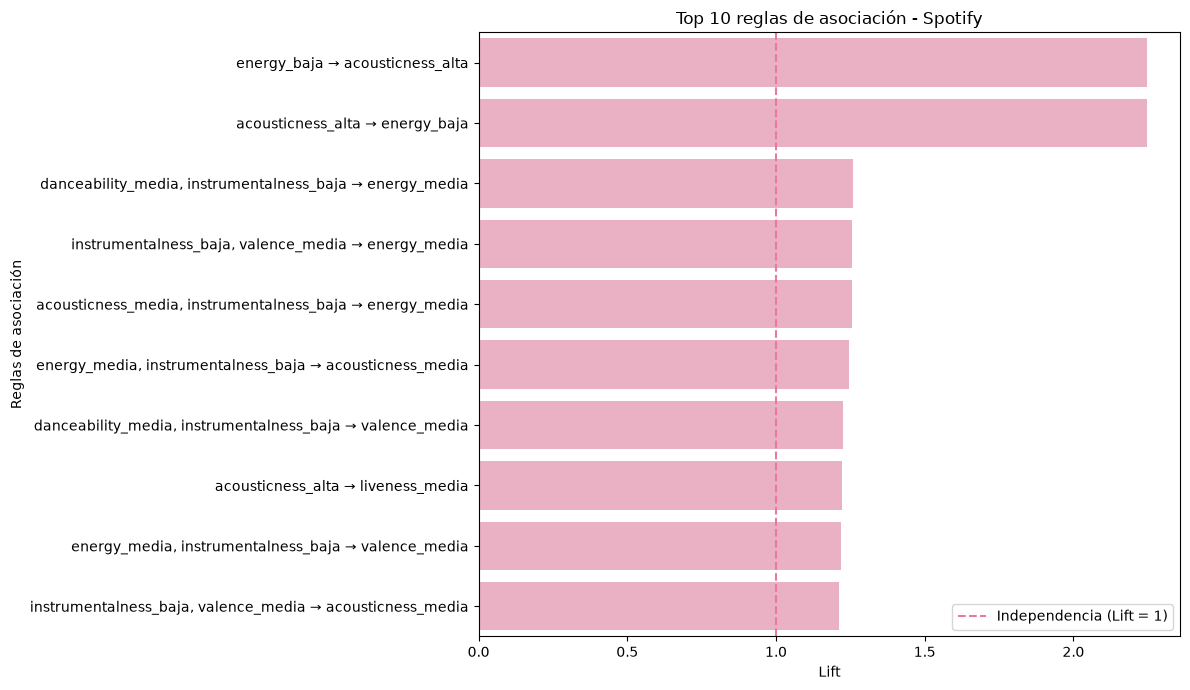

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Seleccionar las 10 reglas con mayor lift
top_reglas = resultados.head(10).copy()

# Crear etiquetas para las reglas
top_reglas["regla"] = (
    top_reglas["antecedents"]
    + " → "
    + top_reglas["consequents"]
)

# Crear la gráfica
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_reglas,
    x="lift",
    y="regla",
    color="#F4A7C1"
)

# Línea de referencia: lift = 1
plt.axvline(
    x=1,
    color="#E879A0",
    linestyle="--",
    label="Independencia (Lift = 1)"
)

plt.title("Top 10 reglas de asociación - Spotify")
plt.xlabel("Lift")
plt.ylabel("Reglas de asociación")
plt.legend()

plt.tight_layout()
plt.show()

### 8. Interpretación de resultados y conclusiones

Para esta actividad se utilizó el dataset de Spotify, compuesto por 2017 canciones. Se analizaron siete características musicales y se aplicó el algoritmo Apriori para identificar patrones y generar reglas de asociación.

**Principales reglas identificadas:**

**1. Energía baja → Acústica alta**

- Soporte: 14.1 %
- Confianza: 56.2 %
- Lift: 2.246

Esta fue la asociación positiva más destacada. El 56.2 % de las canciones clasificadas con energía baja también presentan acústica alta. El lift indica que esta combinación aparece aproximadamente 2.25 veces más de lo esperado si ambas características fueran independientes.

**2. Bailabilidad media + Instrumentalidad baja → Energía media**

- Soporte: 12 %
- Confianza: 62.8 %
- Lift: 1.258

Las canciones que presentan bailabilidad media e instrumentalidad baja tienen una probabilidad del 62.8 % de presentar también energía media. Existe una asociación positiva, aunque más moderada que la anterior.

**3. Acústica alta → Liveness media**

- Soporte: 15.3 %
- Confianza: 61 %
- Lift: 1.223

Se identificó que las canciones con acústica alta presentan frecuentemente valores medios de liveness, una característica relacionada con la probabilidad de que exista público en la grabación.

**4. Instrumentalidad baja → Energía media**

- Soporte: 20.7 %
- Confianza: 60.2 %
- Lift: 1.205

Esta regla indica que el 60.2 % de las canciones con instrumentalidad baja también presentan energía media.

### Conclusión

Mediante el algoritmo Apriori fue posible identificar relaciones entre distintas características musicales del dataset de Spotify.

El hallazgo más relevante fue la asociación entre energía baja y acústica alta, debido a que presentó el mayor lift (2.246).

Esta actividad permitió comprender cómo las reglas de asociación pueden utilizarse para descubrir patrones dentro de un conjunto de datos, incluso cuando no se trata de transacciones comerciales.

Es importante considerar que las categorías alta, media y baja se definieron a partir de la distribución de este dataset y que las asociaciones identificadas no implican relaciones de causa y efecto.

En conclusión, las técnicas de minería de datos permiten transformar características individuales en conocimiento sobre las relaciones que existen entre ellas.